# Step 8 — Nested validation of the SHP2 random forest
Yijie Zhu | 35 published SHP2 inhibitors | November 2026

**Run in JupyterLab:** save this file beside `SHP2_SAR_Workbook.ipynb`, select
**Python (shp2_sar)**, then choose **Run → Run All Cells**. The full run may take
several minutes. Keep the kernel running while the progress messages appear.

This continuation compares four forest settings. The **inner** validation chooses
settings from the outer training compounds; the **outer** validation evaluates
the selected forest on compounds excluded from that selection. It preserves both
original evaluation tasks and the two original baselines.

The notebook includes a frozen copy of the 35 structure/response records from the
previous analysis, so it also runs without the earlier project files. If the
earlier structure/measurement export is present, it checks for disagreement and
stops rather than silently analyzing a different dataset. Each run writes to a new
timestamped subfolder of `results`; the original workbook and exports are preserved.

**Scope:** the target remains percent SHP2 inhibition at 10 μM. No IC50 values,
family labels, compound IDs, or biological results other than the training labels
enter the molecular features. The four candidates were motivated by prior
exploratory results on these same molecules. Nested validation reduces direct
parameter-selection leakage, but does not erase that adaptive history or provide
independent external validation.

This copy contains outputs from a completed verification run. Rerunning it on your Mac creates a new results folder on your computer.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import rdFingerprintGenerator
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd()

if not (ROOT / "data" / "published_measurements.json").exists():
    ROOT = ROOT.parent

assert (ROOT / "data" / "published_measurements.json").exists(), (
    f"Cannot find the SHP2 project folder from {Path.cwd()}"
)
OUT = ROOT / 'results' / ('step8_nested_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
OUT.mkdir(parents=True)
STARTED = time.perf_counter()
print('New results folder:', OUT)
print('Python:', sys.version.split()[0], '| RDKit:', rdBase.rdkitVersion,
      '| scikit-learn:', sklearn.__version__)


New results folder: /Users/zhuyijie/Desktop/SHP2 SAR Project_ml/results/step8_nested_20261118_170039_304543
Python: 3.11.17 | RDKit: 2026.09.1 | scikit-learn: 1.9.1


In [3]:
FROZEN_RECORDS = [{'id': 'SDUY038', 'smiles': 'CC1(N)CCN(C(=O)C2=CC=C(SC3=CC=CC(Cl)=C3Cl)O2)CC1', 'inhibition': 92}, {'id': '1', 'smiles': 'CC1(N)CCN(C(=O)C2=CC=C(SC3=C(Cl)C(Cl)=CC=C3)S2)CC1', 'inhibition': 31}, {'id': '2', 'smiles': 'CC1(N)CCN(C(=O)C2=CC(Br)=C(SC3=C(Cl)C(Cl)=CC=C3)O2)CC1', 'inhibition': 10}, {'id': '3', 'smiles': 'COC(=O)C1=C(SC2=C(Cl)C(Cl)=CC=C2)OC(C(=O)N2CCC(C)(N)CC2)=C1', 'inhibition': 22}, {'id': '4', 'smiles': 'CC1(N)CCN(C(=O)C2=CC(N)=C(SC3=C(Cl)C(Cl)=CC=C3)O2)CC1', 'inhibition': 35}, {'id': '5', 'smiles': 'CC1=C(SC2=C(Cl)C(Cl)=CC=C2)OC(C(=O)N2CCC(C)(N)CC2)=C1', 'inhibition': 15}, {'id': '6', 'smiles': 'CC1(N)CCN(C(=O)C2=CC=C(OC3=CC=CC(Cl)=C3Cl)O2)CC1', 'inhibition': 50}, {'id': '7', 'smiles': 'CC1(N)CCN(C(=O)C2=CC=C(C(=O)C3=CC=CC(Cl)=C3Cl)O2)CC1', 'inhibition': 23}, {'id': '8', 'smiles': 'CC1(N)CCN(C(=O)C2=CC=C(CC3=CC=CC(Cl)=C3Cl)O2)CC1', 'inhibition': 24}, {'id': '9', 'smiles': 'CC1(N)CCN(C(=O)C2=CC=C(SC3=CC4=C(C=CC=C4)C=C3)O2)CC1', 'inhibition': 73}, {'id': '10', 'smiles': 'CC1(N)CCN(C(=O)C2=CC=C(SC3=C(Cl)C(Cl)=NC=C3)O2)CC1', 'inhibition': 87}, {'id': '11', 'smiles': 'CC1(N)CCN(C(=O)C2=CC=C(SC3=C(Cl)C(N)=NC=C3)O2)CC1', 'inhibition': 92}, {'id': '12', 'smiles': 'CC1(N)CCN(C(=O)C2=CC=C(SC3=C(C(F)(F)F)N=CC=C3)O2)CC1', 'inhibition': 38}, {'id': '13', 'smiles': 'CC1(N)CCN(C(=O)C2=CC=C(SC3=C(Cl)C(N)=CC=C3)O2)CC1', 'inhibition': 96}, {'id': '14', 'smiles': 'CC1(NC(=O)C2=CC=CC=C2)CCN(C(=O)C2=CC=C(SC3=CC=CC(Cl)=C3Cl)O2)CC1', 'inhibition': 31}, {'id': '15', 'smiles': 'O=C(C1=CC=C(SC2=C(Cl)C(Cl)=CC=C2)O1)N1CCNCC1', 'inhibition': 70}, {'id': '16', 'smiles': 'NC1CCN(C(=O)C2=CC=C(SC3=C(Cl)C(Cl)=CC=C3)O2)CC1', 'inhibition': 88}, {'id': '17', 'smiles': 'NC1CCN(C(=O)C2=CC=C(SC3=C(Cl)C(Cl)=CC=C3)O2)C1', 'inhibition': 65}, {'id': '18', 'smiles': 'NCC1CCN(C(=O)C2=CC=C(SC3=C(Cl)C(Cl)=CC=C3)O2)CC1', 'inhibition': 59}, {'id': '19', 'smiles': 'N[C@@H]1C2=C(C=CC=C2)CC12CCN(C(=O)C1=CC=C(SC3=C(Cl)C(Cl)=CC=C3)O1)CC2', 'inhibition': 88}, {'id': '20', 'smiles': 'NC1=NC=CC(SC2=CC=C(C(=O)N3CCNCC3)O2)=C1Cl', 'inhibition': 57}, {'id': '21', 'smiles': 'NC1=NC=CC(SC2=CC=C(C(=O)N3CCC(N)CC3)O2)=C1Cl', 'inhibition': 81}, {'id': '22', 'smiles': 'NC1=NC=CC(SC2=CC=C(C(=O)N3CCC(N)C3)O2)=C1Cl', 'inhibition': 54}, {'id': '23', 'smiles': 'NCC1CCN(C(=O)C2=CC=C(SC3=C(Cl)C(N)=NC=C3)O2)CC1', 'inhibition': 57}, {'id': '24', 'smiles': 'NC1=NC=CC(SC2=CC=C(C(=O)N3CCC4(CC3)CC3=C(C=CC=C3)[C@H]4N)O2)=C1Cl', 'inhibition': 99}, {'id': '25', 'smiles': 'NC1=CC=CC(SC2=CC=C(C(=O)N3CCNCC3)O2)=C1Cl', 'inhibition': 59}, {'id': '26', 'smiles': 'NC1=C(SC2=CC=C(C(=O)N3CCC(N)CC3)O2)C=CC=C1Cl', 'inhibition': 86}, {'id': '27', 'smiles': 'NC1=CC=CC(SC2=CC=C(C(=O)N3CCC(N)C3)O2)=C1Cl', 'inhibition': 56}, {'id': '28', 'smiles': 'NCC1CCN(C(=O)C2=CC=C(SC3=C(Cl)C(N)=CC=C3)O2)CC1', 'inhibition': 58}, {'id': '29', 'smiles': 'NC1=CC=CC(SC2=CC=C(C(=O)N3CCC4(CC3)CC3=C(C=CC=C3)[C@H]4N)O2)=C1Cl', 'inhibition': 99}, {'id': '30', 'smiles': 'NC1=CC=CC(SC2=CC=C(C(=O)N3CCC4(CCC[C@H]4N)CC3)O2)=C1Cl', 'inhibition': 74}, {'id': '31', 'smiles': 'NC1=CC=CC(SC2=CC=C(C(=O)N3CCC4(CC3)CC3=C(C=CC=C3F)[C@H]4N)O2)=C1Cl', 'inhibition': 96}, {'id': '32', 'smiles': 'NC1=CC=CC(SC2=CC=C(C(=O)N3CCC4(CC3)CC3=C(C=CC(F)=C3)[C@H]4N)O2)=C1Cl', 'inhibition': 96}, {'id': '33', 'smiles': 'NC1=CC=CC(SC2=CC=C(C(=O)N3CCC4(CC3)CC3=C(C=C(F)C=C3)[C@H]4N)O2)=C1Cl', 'inhibition': 94}, {'id': '34', 'smiles': 'NC1=C(Cl)C(SC2=CC=C(C(=O)N3CCC4(CC3)CC3=C(C=CC=C3)[C@@H]4N)O2)=CC=C1', 'inhibition': 99}]

FAMILIES = {
    'central_ring': ['1','2','3','4','5'],
    'linker': ['6','7','8'],
    'parent_and_aryl_amide': ['SDUY038','9','10','11','12','13','14'],
    'nonspiro_terminal_amine': ['15','16','17','18','20','21','22','23','25','26','27','28'],
    'spirocycle': ['19','24','29','30','31','32','33','34'],
}
family_lookup = {cid:family for family, ids in FAMILIES.items() for cid in ids}
df = pd.DataFrame(FROZEN_RECORDS).rename(columns={
    'id':'compound_id', 'inhibition':'inhibition_10uM_pct'})
df['family'] = df.compound_id.map(family_lookup)
assert len(df)==35 and df.compound_id.nunique()==35 and df.family.notna().all()
assert df.inhibition_10uM_pct.between(0,100).all()
mols = [Chem.MolFromSmiles(s) for s in df.smiles]
assert all(m is not None and len(Chem.GetMolFrags(m))==1 for m in mols)
df['canonical_isomeric_smiles'] = [Chem.MolToSmiles(m,isomericSmiles=True) for m in mols]
df['connectivity_key'] = [Chem.MolToSmiles(m,isomericSmiles=False) for m in mols]
assert not df.canonical_isomeric_smiles.duplicated().any()
for cid, label in [('29','S'),('34','R')]:
    m = mols[df.index[df.compound_id.eq(cid)][0]]
    assert [s for _,s in Chem.FindMolChiralCenters(m,includeUnassigned=True)]==[label]

existing_path = ROOT/'results'/'verified_structures_and_measurements.csv'
if existing_path.exists():
    existing = pd.read_csv(existing_path,dtype={'compound_id':str})
    required = {'compound_id','inhibition_10uM_pct','canonical_isomeric_smiles'}
    if not required.issubset(existing):
        raise ValueError('Existing export is incomplete. Regenerate Section 4 of the original workbook.')
    if existing.compound_id.duplicated().any() or set(existing.compound_id)!=set(df.compound_id):
        raise ValueError('Existing export compound IDs disagree with the frozen 35-compound dataset.')
    current = existing.set_index('compound_id').loc[df.compound_id]
    if not np.allclose(current.inhibition_10uM_pct.to_numpy(float),df.inhibition_10uM_pct.to_numpy(float),rtol=0,atol=1e-8):
        raise ValueError('Existing inhibition values differ. Review provenance before running.')
    canon=[]
    for cid,smi in zip(current.index,current.canonical_isomeric_smiles):
        m=Chem.MolFromSmiles(smi)
        if m is None:
            raise ValueError(f'Invalid existing structure: {cid}')
        canon.append(Chem.MolToSmiles(m,isomericSmiles=True))
    if canon!=df.canonical_isomeric_smiles.tolist():
        raise ValueError('Existing structures differ. Review the affected compound mapping before running.')
    if 'family' in current and current.family.tolist()!=df.family.tolist():
        raise ValueError('Existing family assignments differ. Preserve and review the original splits.')
    print('Existing structure/measurement export agrees with the embedded dataset.')
else:
    print('Using the embedded frozen dataset; no earlier export was found in this directory.')

gen=rdFingerprintGenerator.GetMorganGenerator(radius=2,fpSize=2048,includeChirality=True)
fps=[gen.GetFingerprint(m) for m in mols]
X=np.vstack([gen.GetFingerprintAsNumPy(m) for m in mols])
y=df.inhibition_10uM_pct.to_numpy(float)
keys=df.connectivity_key.to_numpy()
families=df.family.to_numpy()
similarity=np.array([DataStructs.BulkTanimotoSimilarity(fp,fps) for fp in fps])
assert X.shape==(35,2048)
dataset_digest=hashlib.sha256(df.to_json(orient='records').encode()).hexdigest()
df.to_csv(OUT/'frozen_dataset.csv',index=False)
print('Dataset checked:',len(df),'compounds; fingerprint shape:',X.shape)
print('Compounds 20–24 retain the previously documented aminochloropyridinyl CSV structures.')


Existing structure/measurement export agrees with the embedded dataset.
Dataset checked: 35 compounds; fingerprint shape: (35, 2048)
Compounds 20–24 retain the previously documented aminochloropyridinyl CSV structures.


## What is selected, and what remains held out?

The four candidates use 200 trees and seed 42. They cross `max_features` =
`'sqrt'` or `1.0` with `min_samples_leaf` = 2 or 1. Selection minimizes pooled
inner out-of-fold **MAE**, giving each inner held-out molecule one contribution.
An exact tie is resolved by candidate order, with the original settings first.

**Primary evaluation:** outer leave-one-family-out (five folds), with inner
leave-one-family-out among the four remaining families.

**Secondary evaluation:** the same ten connectivity-grouped outer five-fold
splits as before (seeds 42–51), with a fixed four-fold connectivity-grouped inner
split in each outer training set. Identical-connectivity stereoisomers stay
together at both levels.

The mean and nearest-neighbor baselines, original fixed forest, and previously
explored fixed revised forest use exactly the same outer tests. The revised
fixed model remains an exploratory comparator, not the parameter-selection result.


In [4]:
CANDIDATES = [
    {'name':'sqrt_leaf2','max_features':'sqrt','min_samples_leaf':2},
    {'name':'sqrt_leaf1','max_features':'sqrt','min_samples_leaf':1},
    {'name':'all_leaf2','max_features':1.0,'min_samples_leaf':2},
    {'name':'all_leaf1','max_features':1.0,'min_samples_leaf':1},
]

def make_forest(setting):
    return RandomForestRegressor(n_estimators=200,random_state=42,n_jobs=1,
        max_features=setting['max_features'],min_samples_leaf=setting['min_samples_leaf'])

def grouped_splits(connectivity,n_splits,seed):
    unique=np.array(sorted(set(connectivity)))
    if len(unique)<n_splits:
        raise ValueError('Too few connectivity groups for the prespecified inner split.')
    folds=[]
    for a,b in KFold(n_splits=n_splits,shuffle=True,random_state=seed).split(unique):
        tr=np.flatnonzero(np.isin(connectivity,unique[a]))
        te=np.flatnonzero(np.isin(connectivity,unique[b]))
        assert not set(connectivity[tr]) & set(connectivity[te])
        folds.append((tr,te))
    return folds

def select_forest(X_train,y_train,keys_train,families_train,scheme,seed):
    # This function receives only the outer TRAINING data.
    if scheme=='leave_family_out':
        inner=list(LeaveOneGroupOut().split(X_train,y_train,families_train))
    else:
        inner=grouped_splits(keys_train,4,seed)
    inner_rows=[]
    for candidate_index,setting in enumerate(CANDIDATES):
        p=np.full(len(y_train),np.nan)
        seen=np.zeros(len(y_train),dtype=int)
        for a,b in inner:
            assert not set(a) & set(b)
            assert not set(keys_train[a]) & set(keys_train[b])
            fitted=make_forest(setting).fit(X_train[a],y_train[a])
            p[b]=fitted.predict(X_train[b])
            seen[b]+=1
        assert np.isfinite(p).all() and (seen==1).all()
        inner_rows.append({'candidate':setting['name'],'candidate_index':candidate_index,
            'inner_MAE_pp':mean_absolute_error(y_train,p),'n_inner_predictions':len(p)})
    selected_index=int(np.argmin([r['inner_MAE_pp'] for r in inner_rows]))
    return selected_index,inner_rows

prediction_rows=[]
selection_rows=[]
inner_score_rows=[]

def evaluate_outer(scheme,repeat,folds):
    seen=np.zeros(len(y),dtype=int)
    for fold,(train,test) in enumerate(folds):
        assert not set(train) & set(test)
        assert not set(keys[train]) & set(keys[test])
        if scheme=='leave_family_out':
            assert not set(families[train]) & set(families[test])
        inner_seed=1000+10*repeat+fold
        chosen,inner_rows=select_forest(X[train],y[train],keys[train],families[train],scheme,inner_seed)
        for r in inner_rows:
            inner_score_rows.append(dict(scheme=scheme,repeat=repeat,fold=fold,**r))
        selected=CANDIDATES[chosen]
        selection_rows.append(dict(scheme=scheme,repeat=repeat,fold=fold,
            held_out_family=str(families[test[0]]) if scheme=='leave_family_out' else '',
            n_train=len(train),n_test=len(test),selected=selected['name'],
            inner_MAE_pp=inner_rows[chosen]['inner_MAE_pp'],inner_seed=inner_seed))
        forest_predictions={}
        # Reuse fits when selected settings equal a fixed comparator.
        for i in sorted({0,3,chosen}):
            fitted=make_forest(CANDIDATES[i]).fit(X[train],y[train])
            forest_predictions[i]=fitted.predict(X[test])
        sim=similarity[np.ix_(test,train)]
        best=sim.max(axis=1)
        nn=np.array([y[train][np.isclose(s,b)].mean() for s,b in zip(sim,best)])
        predictions={
            'mean_baseline':np.full(len(test),y[train].mean()),
            'nearest_neighbor':nn,
            'original_forest':forest_predictions[0],
            'fixed_revised_forest':forest_predictions[3],
            'nested_forest':forest_predictions[chosen],
        }
        for model,p in predictions.items():
            assert np.isfinite(p).all()
            for k,idx in enumerate(test):
                prediction_rows.append(dict(scheme=scheme,repeat=repeat,fold=fold,
                    compound_id=df.iloc[idx].compound_id,family=families[idx],
                    model=model,observed=float(y[idx]),predicted=float(p[k]),
                    max_train_similarity=float(best[k]),selected=selected['name']))
        seen[test]+=1
        pd.DataFrame(selection_rows).to_csv(OUT/'fold_progress.csv',index=False)
        if scheme=='leave_family_out':
            print(f'Primary fold {fold+1}/5: held out {families[test[0]]}; chose {selected["name"]}',flush=True)
    assert (seen==1).all()

print('Four fixed candidates; no additional model search will be performed.')


Four fixed candidates; no additional model search will be performed.


In [5]:
primary_splits=list(LeaveOneGroupOut().split(X,y,families))
evaluate_outer('leave_family_out',0,primary_splits)
print('Primary nested evaluation complete.')


Primary fold 1/5: held out central_ring; chose sqrt_leaf2
Primary fold 2/5: held out linker; chose sqrt_leaf2
Primary fold 3/5: held out nonspiro_terminal_amine; chose sqrt_leaf1
Primary fold 4/5: held out parent_and_aryl_amide; chose sqrt_leaf1
Primary fold 5/5: held out spirocycle; chose sqrt_leaf2
Primary nested evaluation complete.


In [6]:
for repeat in range(10):
    outer=grouped_splits(keys,5,42+repeat)
    evaluate_outer('grouped_random_5fold',repeat,outer)
    print(f'Secondary repeat {repeat+1}/10 complete; elapsed {(time.perf_counter()-STARTED)/60:.1f} min',flush=True)
print('All nested evaluations complete.')


Secondary repeat 1/10 complete; elapsed 5.6 min
Secondary repeat 2/10 complete; elapsed 5.7 min
Secondary repeat 3/10 complete; elapsed 5.8 min
Secondary repeat 4/10 complete; elapsed 5.9 min
Secondary repeat 5/10 complete; elapsed 6.1 min
Secondary repeat 6/10 complete; elapsed 6.2 min
Secondary repeat 7/10 complete; elapsed 6.3 min
Secondary repeat 8/10 complete; elapsed 6.5 min
Secondary repeat 9/10 complete; elapsed 6.6 min
Secondary repeat 10/10 complete; elapsed 6.7 min
All nested evaluations complete.


PRIMARY: each compound has one outer held-out prediction per model


,model,n,MAE_pp,RMSE_pp,R2
50,fixed_revised_forest,35,29.717,33.262,-0.462
51,mean_baseline,35,27.094,31.640,-0.323
52,nearest_neighbor,35,30.800,39.042,-1.015
53,nested_forest,35,28.999,31.596,-0.319
54,original_forest,35,25.591,28.679,-0.087


SECONDARY: mean and SD across ten repeats; SD is not an independent-data confidence interval


,mean_MAE_pp,SD_MAE_pp,mean_RMSE_pp,mean_R2
model,,,,
fixed_revised_forest,12.671,0.587,17.125,0.612
mean_baseline,24.542,0.623,28.532,-0.077
nearest_neighbor,16.907,1.497,22.923,0.300
nested_forest,13.025,0.943,17.438,0.597
original_forest,18.887,0.695,21.340,0.398


Primary family errors:


model,fixed_revised_forest,mean_baseline,nearest_neighbor,nested_forest,original_forest
family,,,,,
central_ring,41.093,48.767,69.400,39.942,39.942
linker,23.155,35.073,59.667,20.984,20.984
nonspiro_terminal_amine,22.280,9.775,25.333,21.637,13.246
parent_and_aryl_amide,39.409,26.291,29.571,34.119,31.465
spirocycle,27.741,37.236,5.125,31.728,31.728


Inner-selected settings:


selected,all_leaf1,all_leaf2,sqrt_leaf1,sqrt_leaf2
scheme,,,,
grouped_random_5fold,46,1,3,0
leave_family_out,0,0,2,3


Original benchmark reproduced within 0.02 pp: {'mean_baseline': True, 'nearest_neighbor': True, 'original_forest': True}


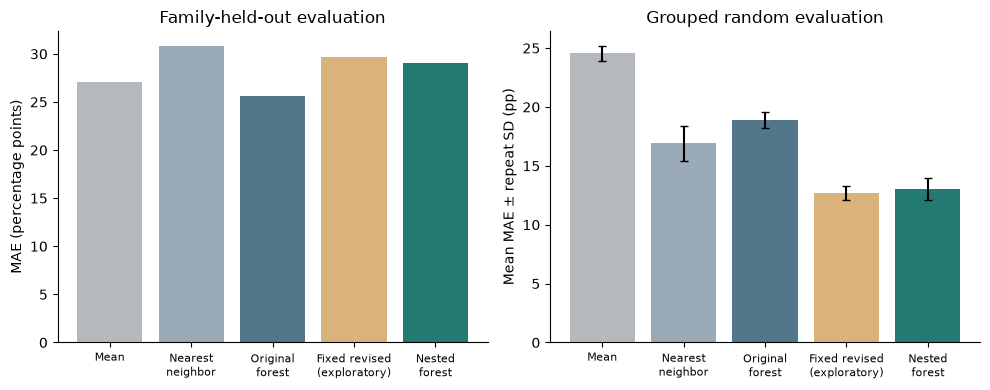

Saved results: /Users/zhuyijie/Desktop/SHP2 SAR Project_ml/results/step8_nested_20261118_170039_304543
Run time: 6.83 minutes


In [7]:
predictions=pd.DataFrame(prediction_rows)
selections=pd.DataFrame(selection_rows)
inner_scores=pd.DataFrame(inner_score_rows)
assert len(selections)==55 and len(inner_scores)==220
assert len(predictions)==35*5*11
assert not predictions.duplicated(['scheme','repeat','model','compound_id']).any()
assert predictions.groupby(['scheme','repeat','model']).size().eq(35).all()
metrics=[]
for (scheme,repeat,model),g in predictions.groupby(['scheme','repeat','model']):
    metrics.append(dict(scheme=scheme,repeat=repeat,model=model,
        n=len(g),MAE_pp=mean_absolute_error(g.observed,g.predicted),
        RMSE_pp=np.sqrt(mean_squared_error(g.observed,g.predicted)),
        R2=r2_score(g.observed,g.predicted)))
metrics=pd.DataFrame(metrics)
primary_metrics=metrics[metrics.scheme.eq('leave_family_out')].drop(columns=['scheme','repeat'])
secondary=metrics[metrics.scheme.eq('grouped_random_5fold')]
secondary_summary=secondary.groupby('model').agg(
    mean_MAE_pp=('MAE_pp','mean'),SD_MAE_pp=('MAE_pp','std'),
    mean_RMSE_pp=('RMSE_pp','mean'),mean_R2=('R2','mean'))
family_metrics=predictions[predictions.scheme.eq('leave_family_out')].assign(
    AE_pp=lambda t:abs(t.observed-t.predicted)).groupby(['family','model']).agg(
        n=('compound_id','size'),MAE_pp=('AE_pp','mean')).reset_index()
print('PRIMARY: each compound has one outer held-out prediction per model')
display(primary_metrics.round(3))
print('SECONDARY: mean and SD across ten repeats; SD is not an independent-data confidence interval')
display(secondary_summary.round(3))
print('Primary family errors:')
display(family_metrics.pivot(index='family',columns='model',values='MAE_pp').round(3))
print('Inner-selected settings:')
display(pd.crosstab(selections.scheme,selections.selected))

for name,frame in [('out_of_fold_predictions.csv',predictions),
    ('selected_settings.csv',selections),('inner_candidate_scores.csv',inner_scores),
    ('metrics_each_repeat.csv',metrics),('primary_metrics.csv',primary_metrics),
    ('family_metrics.csv',family_metrics)]:
    frame.to_csv(OUT/name,index=False)
secondary_summary.to_csv(OUT/'secondary_summary.csv')

# Check that the source reconstruction preserves the original benchmark.
reference={'mean_baseline':27.09365079365079,'nearest_neighbor':30.8,
           'original_forest':25.591448186734}
current=primary_metrics.set_index('model').MAE_pp
agreement={name:bool(abs(current[name]-value)<0.02) for name,value in reference.items()}
print('Original benchmark reproduced within 0.02 pp:',agreement)
if not all(agreement.values()):
    print('Review dataset and software versions before comparing this run with the earlier report.')

fig,axes=plt.subplots(1,2,figsize=(10,4))
order=['mean_baseline','nearest_neighbor','original_forest','fixed_revised_forest','nested_forest']
labels=['Mean','Nearest\nneighbor','Original\nforest','Fixed revised\n(exploratory)','Nested\nforest']
colors=['#b5b8bd','#9aaab7','#52778b','#dab27b','#237a73']
axes[0].bar(range(5),current.loc[order],color=colors)
axes[0].set(title='Family-held-out evaluation',ylabel='MAE (percentage points)')
axes[1].bar(range(5),secondary_summary.loc[order,'mean_MAE_pp'],
    yerr=secondary_summary.loc[order,'SD_MAE_pp'],capsize=3,color=colors)
axes[1].set(title='Grouped random evaluation',ylabel='Mean MAE ± repeat SD (pp)')
for ax in axes:
    ax.set_xticks(range(5),labels,fontsize=8)
    ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
fig.savefig(OUT/'nested_comparison.png',dpi=180,bbox_inches='tight')
plt.show()

provenance={
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'input_source':'Frozen 35-compound structure/single-dose response subset of jm6c00836_si_004.csv; mapped to the original Tables 1–4 project records',
    'source_csv_library_file_id':'libfile_9e924ac5acf8819193bca5880294234a',
    'original_workbook_library_file_id':'libfile_53a7879353b481918927e2a7582dff68',
    'dataset_sha256':dataset_digest,'candidates':CANDIDATES,
    'n_estimators':200,'forest_seed':42,'primary_inner':'leave remaining family out',
    'secondary_inner':'four connectivity-grouped folds, seed=1000+10*repeat+outer_fold',
    'secondary_outer_seeds':list(range(42,52)),
    'versions':{'python':sys.version,'rdkit':rdBase.rdkitVersion,
        'sklearn':sklearn.__version__,'numpy':np.__version__,'pandas':pd.__version__},
    'original_score_check':agreement,
    'interpretation':'Internal adaptive follow-up; candidates were motivated by prior exploration. No independent external validation.',
    'elapsed_seconds':time.perf_counter()-STARTED,
}
(OUT/'provenance.json').write_text(json.dumps(provenance,indent=2)+'\n')
print('Saved results:',OUT)
print('Run time:',round(provenance['elapsed_seconds']/60,2),'minutes')


## Results from the completed verification run

| Evaluation | Original fixed forest MAE | Inner-selected forest MAE |
|---|---:|---:|
| Repeated grouped random CV | 18.89 ± 0.69 pp | **13.02 ± 0.94 pp** |
| Leave-one-family-out | **25.59 pp** | 29.00 pp |

The grouped-random MAE decreased by approximately **31%** relative to the original
forest. These are internal follow-up results on the same 35 compounds. Repeat SD
describes split sensitivity, not a confidence interval from independent datasets.

Inner selection chose all features with leaf size 1 in **46 of 50** grouped-random
outer folds; it chose all features with leaf size 2 once and sqrt features with leaf
size 1 three times. For family holdout, it chose the original sqrt/leaf-2 setting in
three folds and sqrt/leaf-1 in two. Thus selection was fairly consistent for the
within-series task, while family transfer remained poor. Do not present the new
within-series score as validation for unfamiliar chemical series.

The original mean, nearest-neighbor, and forest benchmarks were reproduced within
0.02 percentage points. The machine-readable exports contain the full-precision
values and every inner and outer prediction record.

## Read the results

- Compare **nested_forest** with the original forest, mean, and nearest neighbor
  separately in each evaluation. Lower MAE is better. RMSE emphasizes large errors.
- **fixed_revised_forest** uses all features and leaf size 1 regardless of inner
  results. Its score is retained to show whether the earlier exploratory improvement
  survives a training-only selection procedure; it is not itself a nested selection.
- Check `selected_settings.csv` to see whether the same setting is chosen across
  outer folds. The settings chosen after fitting each outer training set may differ;
  this is expected in nested validation.
- Do not use the outer results to keep adding candidates until a preferred score
  appears. Report this four-candidate experiment, including any deterioration.
- An improvement in grouped random evaluation does not establish transfer to new
  structural families. Neither evaluation is an external prospective test.

`out_of_fold_predictions.csv` preserves every prediction; `inner_candidate_scores.csv`
shows exactly what selected the parameters. The original data conflict for compounds
20–24 remains the documented source interpretation; no structures or activities
were changed to improve scores.

Methods reference: [scikit-learn nested versus non-nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).
Experimental data: Zhu et al., J. Med. Chem. 2026, 69, 14774–14803,
[DOI: 10.1021/acs.jmedchem.6c00836](https://doi.org/10.1021/acs.jmedchem.6c00836).
